In [ ]:
import numpy as np
from PIL import Image
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt

In [7]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
dataset = np.load("./datasets/nails_disease_dataset_training_multi_class.npz")
X_train = dataset["X_train"]
y_train = dataset["y_train"]

In [4]:
X_train[y_train==0].shape,X_train[y_train==1].shape,X_train[y_train==2].shape,X_train[y_train==3].shape,X_train[y_train==4].shape,X_train[y_train==5].shape,X_train[y_train==6].shape,X_train[y_train==7].shape

((571, 224, 224, 3),
 (735, 224, 224, 3),
 (603, 224, 224, 3),
 (767, 224, 224, 3),
 (677, 224, 224, 3),
 (639, 224, 224, 3),
 (575, 224, 224, 3),
 (341, 224, 224, 3))

In [5]:
augmenter = models.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.10),
        layers.RandomZoom((-0.15, 0.15)),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomBrightness(0.15),
        layers.RandomContrast(0.15),
    ],
)

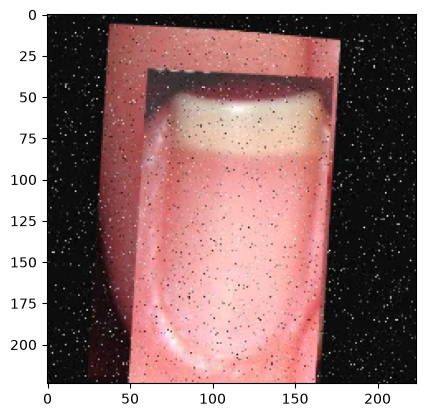

In [6]:
plt.imshow(X_train[37]/255);

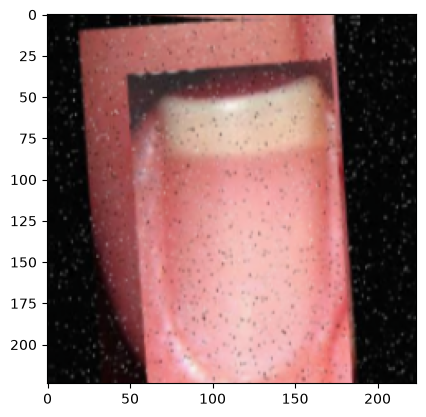

In [7]:
plt.imshow(augmenter(X_train[37])/255);

In [8]:
def augment_data(minority, target):
    aug_list = []
    count = len(minority)
    while count < target:
        r_index = np.random.randint(0, len(minority))
        random_img = minority[r_index]
        augmented_img = augmenter(random_img, training=True)

        aug_list.append(augmented_img)
        count += 1

    aug_list = np.array(aug_list)

    result = np.concatenate([minority, aug_list])
    return result

In [9]:
X0_train_augmented = augment_data(X_train[y_train==0],1000)
X0_train_augmented.shape

(1000, 224, 224, 3)

In [10]:
X1_train_augmented = augment_data(X_train[y_train==1],1000)
X1_train_augmented.shape

(1000, 224, 224, 3)

In [11]:
X2_train_augmented = augment_data(X_train[y_train==2],1000)
X2_train_augmented.shape

(1000, 224, 224, 3)

In [12]:
X3_train_augmented = augment_data(X_train[y_train==3],1000)
X3_train_augmented.shape

(1000, 224, 224, 3)

In [13]:
X4_train_augmented = augment_data(X_train[y_train==4],1000)
X4_train_augmented.shape

(1000, 224, 224, 3)

In [14]:
X5_train_augmented = augment_data(X_train[y_train==5],1000)
X5_train_augmented.shape

(1000, 224, 224, 3)

In [15]:
X6_train_augmented = augment_data(X_train[y_train==6],1000)
X6_train_augmented.shape

(1000, 224, 224, 3)

In [16]:
X7_train_augmented = augment_data(X_train[y_train==7],1000)
X7_train_augmented.shape

(1000, 224, 224, 3)

In [17]:
X_train_augmented_combined = np.concatenate([
    X0_train_augmented,
    X1_train_augmented,
    X2_train_augmented,
    X3_train_augmented,
    X4_train_augmented,
    X5_train_augmented,
    X6_train_augmented,
    X7_train_augmented
],axis = 0)

In [21]:
X_train_augmented_combined.shape

(8000, 224, 224, 3)

In [18]:
y0_train = np.full(X0_train_augmented.shape[0],0)
y1_train = np.full(X1_train_augmented.shape[0],1)
y2_train = np.full(X2_train_augmented.shape[0],2)
y3_train = np.full(X3_train_augmented.shape[0],3)
y4_train = np.full(X4_train_augmented.shape[0],4)
y5_train = np.full(X5_train_augmented.shape[0],5)
y6_train = np.full(X6_train_augmented.shape[0],6)
y7_train = np.full(X7_train_augmented.shape[0],7)

In [19]:
y_train_augmented_combined = np.concatenate([y0_train,y1_train,y2_train,y3_train,y4_train,y5_train,y6_train,y7_train])

In [20]:
y_train_augmented_combined.shape

(8000,)

In [22]:
np.savez_compressed("nails_training_dataset_multi_class_augmented",X_train = X_train_augmented_combined,y_train = y_train_augmented_combined)